In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Usted es la persona responsable del proyecto de **reforma del laboratorio de instrumentación** de una escuela de ingeniería. El laboratorio tiene que estar operativo para el inicio del curso, dentro de **16 semanas**. El plan aprobado es el que se adjunta (duraciones en semanas; costes en k€). Las duraciones tope y los costes unitarios de reducción (CUR) son los que el contratista ha ofrecido por contrato para las actividades que ejecuta (A, C, G, I); las demás no pueden acelerarse (CUR infinito). La última columna es la desviación típica estimada de cada duración.

In [4]:
#| tbl-cap: "Plan aprobado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, descripcion                                       , predecessor, duration, tope, CUR   , sd 
    ('A'     , 'Desmontaje y retirada del laboratorio antiguo'   , '---'      , 3       , 1   , 2     , 0.3),
    ('B'     , 'Proyecto eléctrico y permisos'                   , '---'      , 4       , 4   , np.inf, 0.5),
    ('C'     , 'Obra civil: tabiques, suelo técnico y pintura'   , 'A'        , 5       , 3   , 6     , 0.8),
    ('D'     , 'Instalación eléctrica'                           , 'B,C'      , 3       , 3   , np.inf, 0.5),
    ('E'     , 'Climatización y extracción de gases'             , 'C'        , 3       , 3   , np.inf, 0.6),
    ('F'     , 'Mobiliario de laboratorio (suministro y montaje)', 'C'        , 4       , 4   , np.inf, 1  ),
    ('G'     , 'Instalación del equipamiento científico'         , 'D,E,F'    , 2       , 1   , 9     , 0.4),
    ('H'     , 'Inspección de seguridad'                         , 'D,E'      , 1       , 1   , np.inf, 0.2),
    ('I'     , 'Puesta en marcha y formación del personal'       , 'G,H'      , 2       , 1   , 5     , 0.3),
], columns=['activity', 'descripcion', 'predecessor', 'duration', 'tope', 'CUR', 'sd']).set_index('activity')
datos_enunciado.replace(np.inf, '—')

,descripcion,predecessor,duration,tope,CUR,sd
activity,,,,,,
A,Desmontaje y retirada del laboratorio antiguo,---,3,1,2.0,0.3
B,Proyecto eléctrico y permisos,---,4,4,—,0.5
C,"Obra civil: tabiques, suelo técnico y pintura",A,5,3,6.0,0.8
D,Instalación eléctrica,"B,C",3,3,—,0.5
E,Climatización y extracción de gases,C,3,3,—,0.6
F,Mobiliario de laboratorio (suministro y montaje),C,4,4,—,1.0
G,Instalación del equipamiento científico,"D,E,F",2,1,9.0,0.4
H,Inspección de seguridad,"D,E",1,1,—,0.2
I,Puesta en marcha y formación del personal,"G,H",2,1,5.0,0.3


En la semana 1 (acaba de empezar el desmontaje y todo va según el plan) recibe, el mismo día, los siguientes mensajes.

> **De: Proveedor del mobiliario (Labtec S. L.)**
> Lamentamos comunicarles que, por un problema de suministro de encimeras, la entrega e instalación del mobiliario (actividad F) necesitará **2 semanas más** de lo previsto: 6 en lugar de 4. Podríamos entregar en la fecha prevista las mesas de trabajo, que son la parte principal del pedido (2 semanas de montaje), y el resto 2 semanas después de lo previsto, si eso les sirve de algo. Sentimos las molestias.

> **De: Inspector de seguridad (Servicio de Prevención)**
> He revisado el plan que me envió. No puedo dar por válida una inspección realizada antes de que el equipamiento científico esté instalado (actividad G): la inspección (H) debe hacerse **después de G**, no sólo después de la instalación eléctrica y la climatización. Mantengo la duración de una semana.

> **De: Contratista (Obras Lince S. A.)**
> Hemos sabido lo del mobiliario. Les recordamos que el contrato contempla acelerar A, C, G e I a los precios acordados (CUR). Si nos lo piden esta semana podemos aún acortar A, que está en ejecución, y replanificar C. Para G e I habría que planificar turnos de tarde, con un recargo ya incluido en el CUR. Esperamos instrucciones.

> **De: Vicerrectora de Infraestructuras (cliente)**
> Me dicen que el laboratorio podría no estar para el inicio del curso. Cada semana que el laboratorio no esté disponible tendremos que alquilar un espacio externo para las prácticas, que cuesta **4 k€ por semana**. Necesito saber cuánto se va a retrasar y qué proponéis, y lo necesito mañana.

> **De: Gerencia (control presupuestario)**
> El proyecto tiene una bolsa para imprevistos de **4 k€**. Cualquier gasto adicional por encima de esa cifra requiere una modificación presupuestaria que tardaría en aprobarse al menos un mes. Los costes del alquiler de espacios externos saldrían de otra partida (la de docencia), no de la del proyecto.

> **De: Técnico de laboratorio (usuario final)**
> Si hace falta, nosotros podemos ir instalando el equipamiento sobre las mesas de trabajo aunque falten los armarios y la campana; lo hemos hecho otras veces. Y la formación (I) podría solaparse con la instalación si nos dejan entrar antes. Lo que no podemos es empezar el curso sin la inspección.

Responda a las preguntas siguientes **antes** de decidir. En la penúltima se le pide la decisión y cómo la comunicaría a cada uno de los implicados (proveedor, inspector, contratista, vicerrectora, gerencia, técnico de laboratorio).

In [5]:
pregunta_1 = "1. Reconstruya el plan original (calendario, camino crítico, holguras) y después el plan tal como queda con los dos mensajes que cambian los datos: el retraso del mobiliario y la nueva exigencia del inspector. ¿Cuánto se retrasa el proyecto si no se hace nada? Separe el efecto de cada mensaje: ¿cuánto retraso aporta el proveedor, cuánto el inspector y por qué (o por qué no) se suman tal cual?  "
pregunta_2 = "2. Evalúe la oferta del contratista con el algoritmo de Ackoff-Sasieni: ¿qué cuesta recuperar 1, 2, …, 3 semanas y qué actividades habría que acortar en cada caso? Ponga esos costes frente al coste del retraso (4 k€ por semana) y frente al tope de 4 k€ de Gerencia. ¿Qué opción minimiza el coste total para la universidad? ¿Y cuál respeta el tope del proyecto?  "
pregunta_3 = "3. Con las desviaciones típicas dadas, calcule para cada opción la probabilidad de tener el laboratorio en la semana 16 y el retraso esperado. ¿Cambia la respuesta anterior cuando se tiene en cuenta la incertidumbre? ¿Qué opción es más robusta?  "
pregunta_4 = "4. Hay propuestas que no cuestan dinero: la entrega parcial del mobiliario, la inspección en dos fases y el solape que propone el técnico. Modele las que le parezcan aceptables como cambios en el cuadro de prelaciones y cuantifique cuánto plazo recuperan. ¿Qué riesgos tienen y a quién habría que preguntar antes de contar con ellas?  "
pregunta_5 = "5. Tome una decisión: qué combinación de reducciones y negociaciones propone, cuánto cuesta, qué plazo promete a la vicerrectora y con qué probabilidad. Redacte en tres o cuatro líneas el mensaje de respuesta a cada uno de los seis implicados.  "
pregunta_6 = "6. Mirando atrás: ¿qué habría tenido que hacerse en la planificación para que estos mensajes no fueran una sorpresa? Identifique al menos dos fallos de gestión de interesados y uno de gestión de riesgos.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Reconstruya el plan original (calendario, camino crítico, holguras) y después el plan tal como queda con los dos mensajes que cambian los datos: el retraso del mobiliario y la nueva exigencia del inspector. ¿Cuánto se retrasa el proyecto si no se hace nada? Separe el efecto de cada mensaje: ¿cuánto retraso aporta el proveedor, cuánto el inspector y por qué (o por qué no) se suman tal cual?  

2. Evalúe la oferta del contratista con el algoritmo de Ackoff-Sasieni: ¿qué cuesta recuperar 1, 2, …, 3 semanas y qué actividades habría que acortar en cada caso? Ponga esos costes frente al coste del retraso (4 k€ por semana) y frente al tope de 4 k€ de Gerencia. ¿Qué opción minimiza el coste total para la universidad? ¿Y cuál respeta el tope del proyecto?  

3. Con las desviaciones típicas dadas, calcule para cada opción la probabilidad de tener el laboratorio en la semana 16 y el retraso esperado. ¿Cambia la respuesta anterior cuando se tiene en cuenta la incertidumbre? ¿Qué opción es más robusta?  

4. Hay propuestas que no cuestan dinero: la entrega parcial del mobiliario, la inspección en dos fases y el solape que propone el técnico. Modele las que le parezcan aceptables como cambios en el cuadro de prelaciones y cuantifique cuánto plazo recuperan. ¿Qué riesgos tienen y a quién habría que preguntar antes de contar con ellas?  

5. Tome una decisión: qué combinación de reducciones y negociaciones propone, cuánto cuesta, qué plazo promete a la vicerrectora y con qué probabilidad. Redacte en tres o cuatro líneas el mensaje de respuesta a cada uno de los seis implicados.  

6. Mirando atrás: ¿qué habría tenido que hacerse en la planificación para que estos mensajes no fueran una sorpresa? Identifique al menos dos fallos de gestión de interesados y uno de gestión de riesgos.  

# Resolución

In [6]:
def proyecto_de(predecesoras, duraciones, nombres):
    '''Tabla de datos y proyecto pmULE a partir de listas de predecesoras y duraciones.'''
    df = pd.DataFrame({'predecessor': list(predecesoras), 'duration': list(duraciones)}, index=list(nombres))
    df.index.name = 'activity'
    p = PredecessorTable.from_dataframe_of_strings(df, activity='activity', predecessor='predecessor').create_project()
    return df, p

def camino_critico(p, d):
    return '; '.join('–'.join(ruta) for ruta in p.critical_path(d).values())

def resumen_prob(p, d, sd, plazo):
    '''Duración media, desviación típica del camino crítico (la mayor si hay varios), P(T ≤ plazo) y retraso esperado.'''
    R = p.path_matrix(dummies=False)
    L = R @ d.reindex(R.columns)
    V = R @ (sd.reindex(R.columns).fillna(0) ** 2)
    T = float(L.max()); sigma = float(np.sqrt(V[L == T].max()))
    z = (plazo - T) / sigma
    retraso_esp = sigma * (norm.pdf(z) - z * norm.cdf(-z))      # E[máx(0, X − plazo)] con X ~ N(T, σ)
    return T, sigma, float(norm.cdf(z)), float(retraso_esp)

In [7]:
plazo, coste_semana, bolsa = 16, 4, 4
datos_proyecto = datos_enunciado.copy()
sd = datos_proyecto['sd']
preds = datos_proyecto['predecessor'].tolist(); nombres = datos_proyecto.index.tolist()
dur0 = datos_proyecto['duration']
durF = dur0.copy(); durF['F'] += 2                                   # retraso del mobiliario
predsH = list(preds); predsH[nombres.index('H')] = 'D,E,G'                 # inspección tras G
df0, p0 = proyecto_de(preds, dur0, nombres)
dfF, pF = proyecto_de(preds, durF, nombres)
dfH, pH = proyecto_de(predsH, dur0, nombres)
df2, p2 = proyecto_de(predsH, durF, nombres)

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Reconstruya el plan original (calendario, camino crítico, holguras) y después el plan tal como queda con los dos mensajes que cambian los datos: el retraso del mobiliario y la nueva exigencia del inspector. ¿Cuánto se retrasa el proyecto si no se hace nada? Separe el efecto de cada mensaje: ¿cuánto retraso aporta el proveedor, cuánto el inspector y por qué (o por qué no) se suman tal cual?  

Plan original: 16 semanas justas, con el camino crítico A–C–F–G–I. El mobiliario (F) ya era crítico, y la inspección (H) tenía 2 semanas de holgura.

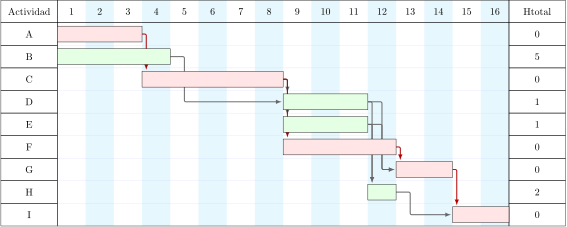

In [9]:
#| fig-cap: "Plan original: Gantt de inicios más tempranos con flechas de prelación y holgura total"
#| label: fig-gantt0
_g, _d = p0.gantt(df0, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_d)

In [ ]:
p0.display_roy_pasos(dur0)

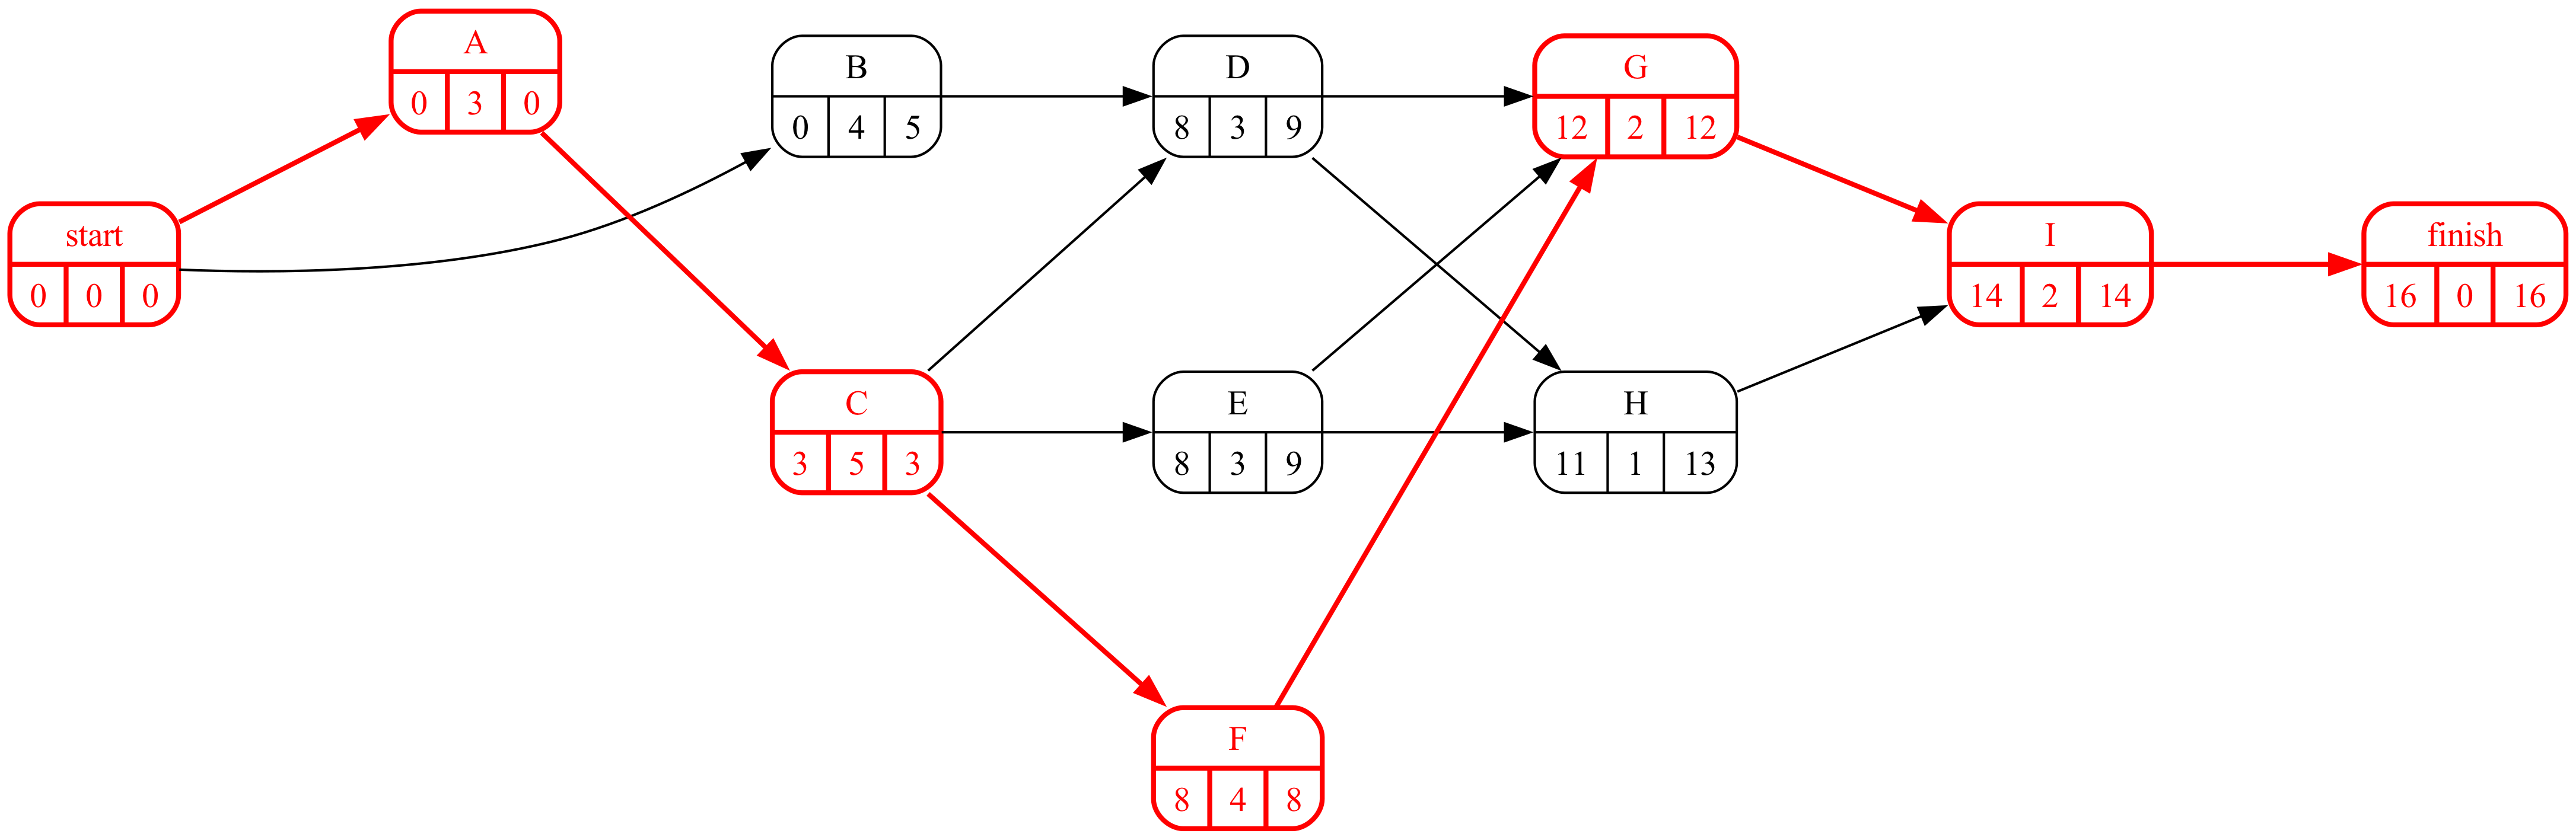

In [10]:
#| fig-cap: "Grafo Roy del plan original con los tiempos"
#| label: fig-grafo0
p0.roy(durations=dur0, ranksep=1.2, nodesep=1.2)

In [11]:
#| tbl-cap: "Calendario del plan original"
#| label: tbl-calendario0
cal0 = p0.calendar(dur0)
cal0[['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total', 'H_libre']]

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total,H_libre
activity,,,,,,
A,0,3,0,3,0,0
B,0,4,5,9,5,4
C,3,8,3,8,0,0
D,8,11,9,12,1,0
E,8,11,9,12,1,0
F,8,12,8,12,0,0
G,12,14,12,14,0,0
H,11,12,13,14,2,2
I,14,16,14,16,0,0


Efecto de cada mensaje por separado y de los dos juntos:

In [12]:
#| tbl-cap: "Las cuatro situaciones"
#| label: tbl-situaciones
filas = []
for nombre, df, p in (('plan original', df0, p0), ('sólo el retraso del mobiliario (F = 6)', dfF, pF),
                      ('sólo la inspección tras G', dfH, pH), ('los dos cambios', df2, p2)):
    T = int(p.duration(df['duration']))
    filas.append({'situación': nombre, 'duración': T, f'retraso sobre {plazo}': T - plazo, 'camino crítico': camino_critico(p, df['duration'])})
pd.DataFrame(filas).set_index('situación')

,duración,retraso sobre 16,camino crítico
situación,,,
plan original,16,0,A–C–F–G–I
sólo el retraso del mobiliario (F = 6),18,2,A–C–F–G–I
sólo la inspección tras G,17,1,A–C–F–G–H–I
los dos cambios,19,3,A–C–F–G–H–I


El proveedor aporta 2 semanas porque F era crítica: su retraso va entero al plazo. El inspector aporta 1: H tenía 2 semanas de holgura, pero al pasar detrás de G deja de aprovecharla y se coloca en el camino crítico (A–C–F–G–H–I). Los efectos se suman (2 + 1 = 3) porque los dos cambios caen sobre la misma ruta; no se sumarían si uno de ellos afectara a una ruta con holgura suficiente para absorberlo.

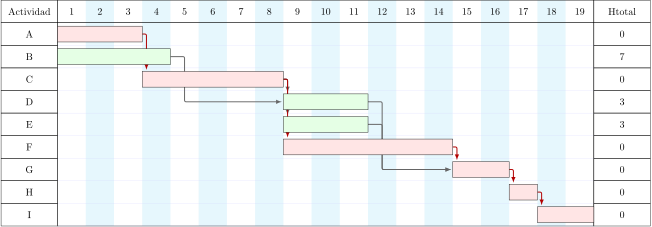

In [13]:
#| fig-cap: "Plan con los dos cambios: 19 semanas"
#| label: fig-gantt2
_g, _d = p2.gantt(df2, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_d)

## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. Evalúe la oferta del contratista con el algoritmo de Ackoff-Sasieni: ¿qué cuesta recuperar 1, 2, …, 3 semanas y qué actividades habría que acortar en cada caso? Ponga esos costes frente al coste del retraso (4 k€ por semana) y frente al tope de 4 k€ de Gerencia. ¿Qué opción minimiza el coste total para la universidad? ¿Y cuál respeta el tope del proyecto?  

Ackoff-Sasieni acorta en cada paso, una semana, el conjunto más barato de actividades que corta todos los caminos críticos del momento (una por camino). Las actividades sin oferta del contratista tienen CUR infinito y nunca se eligen; la duración tope de F es la nueva (el proveedor ya ha dicho lo que tarda).

In [15]:
#| tbl-cap: "Opciones de reducción frente al coste del alquiler"
#| label: tbl-opciones
tope = datos_proyecto['tope'].copy(); tope['F'] = durF['F']
cur = datos_proyecto['CUR'].astype(float)
retraso = int(p2.duration(durF)) - plazo
opciones, duraciones_opcion = [], {0: durF.copy()}
opciones.append({'semanas recuperadas': 0, 'actividades acortadas': '—', 'sobrecoste (k€)': 0.0, 'duración': plazo + retraso})
for r in range(1, retraso + 1):
    _, pasos, dur, _ = p2.ackoff(durF, tope, cur, reduction=r, report=False)
    duraciones_opcion[r] = dur.reindex(durF.index)
    opciones.append({'semanas recuperadas': r, 'actividades acortadas': ', '.join(a for acts in pasos.values() for a in acts),
                     'sobrecoste (k€)': float(sum(cur[a] for acts in pasos.values() for a in acts)), 'duración': int(p2.duration(dur))})
tabla = pd.DataFrame(opciones).set_index('semanas recuperadas')
tabla['retraso'] = (tabla['duración'] - plazo).clip(lower=0)
tabla['alquiler (k€)'] = coste_semana * tabla['retraso']
tabla['coste total universidad (k€)'] = tabla['sobrecoste (k€)'] + tabla['alquiler (k€)']
tabla[f'dentro de la bolsa de {bolsa} k€'] = tabla['sobrecoste (k€)'] <= bolsa
tabla

,actividades acortadas,sobrecoste (k€),duración,retraso,alquiler (k€),coste total universidad (k€),dentro de la bolsa de 4 k€
semanas recuperadas,,,,,,,
0,—,0.0,19,3,12,12.0,True
1,A,2.0,18,2,8,10.0,True
2,"A, A",4.0,17,1,4,8.0,True
3,"A, A, I",9.0,16,0,0,9.0,False


Para recuperar 2 semanas el algoritmo acorta A (2 semanas) (las más baratas por semana); G, con CUR 9, sólo entra cuando las demás agotan su margen. Lo que se ve:

- Sin hacer nada: 3 semanas de alquiler, 12 k€, que además salen de la partida de docencia.
- Recuperar **1** semana cuesta 2 k€ y deja 2 de alquiler (8 k€): 10 k€ en total.
- Recuperar **2** semanas cuesta 4 k€ y deja 1 de alquiler (4 k€): 8 k€ en total: **el mínimo para la universidad** y dentro de la bolsa del proyecto.
- Recuperar **3** semanas cuesta 9 k€ y deja 0 de alquiler (0 k€): 9 k€ en total: supera la bolsa en 5 k€ (modificación presupuestaria, un mes de espera).

Obsérvese el conflicto entre perspectivas: para el proyecto (Gerencia) lo barato es no gastar; para la universidad el alquiler es un coste real aunque salga de otra partida; para la vicerrectora el plazo tiene además un coste reputacional que no está en la tabla.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. Con las desviaciones típicas dadas, calcule para cada opción la probabilidad de tener el laboratorio en la semana 16 y el retraso esperado. ¿Cambia la respuesta anterior cuando se tiene en cuenta la incertidumbre? ¿Qué opción es más robusta?  

Para cada opción se toma la duración media del camino crítico y la varianza de ese camino (suma de las varianzas de sus actividades; si hay varios caminos críticos, la mayor), y se supone normalidad (teorema central del límite). El retraso esperado es $E[\max(0, T - \text{plazo})]$.

In [17]:
#| tbl-cap: "Probabilidad de cumplir el plazo y coste esperado de cada opción"
#| label: tbl-probabilidad
filas = []
for r, dur in duraciones_opcion.items():
    T, sigma, prob, retraso_esp = resumen_prob(p2, dur, sd, plazo)
    sobre = float(tabla.loc[r, 'sobrecoste (k€)'])
    filas.append({'semanas recuperadas': r, 'duración media': T, 'σ': round(sigma, 2), f'P(terminar ≤ {plazo})': round(prob, 3),
                  'retraso esperado (sem)': round(retraso_esp, 2), 'alquiler esperado (k€)': round(coste_semana * retraso_esp, 1),
                  'coste total esperado (k€)': round(sobre + coste_semana * retraso_esp, 1)})
pd.DataFrame(filas).set_index('semanas recuperadas')

,duración media,σ,P(terminar ≤ 16),retraso esperado (sem),alquiler esperado (k€),coste total esperado (k€)
semanas recuperadas,,,,,,
0,19.0,1.42,0.017,3.01,12.0,12.0
1,18.0,1.42,0.080,2.05,8.2,10.2
2,17.0,1.42,0.241,1.20,4.8,8.8
3,16.0,1.42,0.500,0.57,2.3,11.3


La desviación típica del camino crítico es de 1.4 semanas, grande comparada con las diferencias que se están discutiendo. Dos consecuencias: la opción «recuperar 3 semanas» promete terminar en la semana 16 *en media*, es decir, con un 50% de probabilidad, no con seguridad; y en coste esperado la mejor opción es recuperar 2 semanas (8.8 k€ frente a 11.3 de la de 3), la misma que sin incertidumbre. Con la incertidumbre delante, las reducciones de pago compran menos de lo que parecían, y las medidas que recortan plazo sin coste (apartado 4) ganan valor.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Hay propuestas que no cuestan dinero: la entrega parcial del mobiliario, la inspección en dos fases y el solape que propone el técnico. Modele las que le parezcan aceptables como cambios en el cuadro de prelaciones y cuantifique cuánto plazo recuperan. ¿Qué riesgos tienen y a quién habría que preguntar antes de contar con ellas?  

Tres propuestas aparecen en los mensajes. Modeladas como cambios del cuadro de prelaciones:

- **Inspección en dos fases.** La parte eléctrica y de climatización (lo que H comprobaba originalmente) se inspecciona tras D y E, y tras G queda sólo una comprobación final corta. Si el inspector acepta que esa comprobación quepa dentro de la puesta en marcha (I), H vuelve a estar en paralelo y el proyecto recupera la semana que había añadido el inspector.
- **Entrega parcial del mobiliario.** Si G puede empezar sobre las mesas (F1, 2 semanas, en plazo) y el resto del mobiliario (F2, 6 semanas desde el fin de la obra civil) sólo tiene que estar antes de la puesta en marcha, F deja de retrasar a G.
- **Solapar formación e instalación.** Es una relación comienzo-comienzo entre G e I en vez de fin-comienzo; recorta como mucho una semana, pero la formación sobre un equipo a medio instalar es de peor calidad y el técnico lo propone como última opción. No se cuenta con ella.

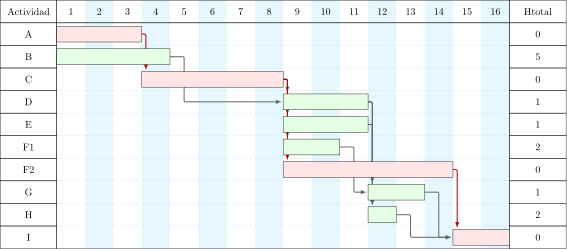

In [19]:
#| fig-cap: "Con inspección en dos fases y entrega parcial del mobiliario (F1 mesas, F2 resto): 16 semanas sin gastar"
#| label: fig-gantt4
nombres4 = ['A', 'B', 'C', 'D', 'E', 'F1', 'F2', 'G', 'H', 'I']
preds4 = ['---', '---', 'A', 'B,C', 'C', 'C', 'C', 'D,E,F1', 'D,E', 'G,H,F2']
dur4 = pd.Series([3, 4, 5, 3, 3, 2, 6, 2, 1, 2], index=nombres4)
sd4 = sd.drop('F'); sd4['F1'], sd4['F2'] = sd['F'] * 0.5, sd['F']
df4, p4 = proyecto_de(preds4, dur4, nombres4)
_g, _d = p4.gantt(df4, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_d)

In [20]:
cal4 = p4.calendar(dur4)
T4, sigma4, prob4, _ = resumen_prob(p4, dur4, sd4, plazo)
Markdown(f'''Duración: **{int(p4.duration(dur4))} semanas** (P(≤ {plazo}) = {prob4:.2f}); camino crítico {camino_critico(p4, dur4)}. F2 (el resto del mobiliario) termina en la semana {int(cal4.loc['F2', 'fin_mas_temprano'])} con holgura {int(cal4.loc['F2', 'H_total'])}.''')

Duración: **16 semanas** (P(≤ 16) = 0.50); camino crítico A–C–F2–I. F2 (el resto del mobiliario) termina en la semana 14 con holgura 0.

Con las dos negociaciones el plan vuelve a 16 semanas en media sin gastar un euro, pero fíjese en que F2 queda crítica: cualquier semana más del proveedor vuelve a retrasar el proyecto. Los riesgos y a quién preguntar: al inspector, si acepta la inspección en dos fases por escrito; al proveedor, qué garantía da de las 2 semanas; al técnico, si instalar sobre las mesas sin campana ni armarios es seguro y no obliga a desmontar después; y a Gerencia, si la bolsa puede reservarse para una reducción *contingente* (acortar I al final sólo si F2 se retrasa).

## Apartado 5

In [21]:
display(Markdown(pregunta_5))

5. Tome una decisión: qué combinación de reducciones y negociaciones propone, cuánto cuesta, qué plazo promete a la vicerrectora y con qué probabilidad. Redacte en tres o cuatro líneas el mensaje de respuesta a cada uno de los seis implicados.  

No hay una única respuesta correcta; sí hay respuestas mal justificadas. Una decisión defendible con los números anteriores:

1. Negociar hoy la inspección en dos fases y la entrega parcial del mobiliario (coste cero; recuperan 3 de las 3 semanas si el proveedor cumple con F2).
2. Contratar ya la reducción de A (2 k€): es la más barata, A está en curso y cada semana ganada ahora es margen contra la incertidumbre del proveedor. Con ello la duración media baja a 15 y la probabilidad de terminar en la 16 sube del 50% al 77%.
3. Reservar la reducción de I (5 k€) como medida contingente: se decide en la semana 13, cuando se sepa si F2 ha llegado. Sobrecoste máximo 7 k€, que supera la bolsa de 4 k€ en 3 k€: habría que pedir a Gerencia la ampliación ya, por si acaso.
4. Prometer a la vicerrectora la semana 16 con probabilidad alta y la 17 como peor caso razonable, y pedirle que no comprometa el alquiler externo hasta la semana 13.

Mensajes (un ejemplo de tono y contenido):

- *Vicerrectora:* «El retraso sin actuar sería de 3 semanas. Con dos cambios de secuencia ya acordados y una reducción de 2 k€ recuperamos el plazo en media; mantengo una reserva de 5 k€ para asegurar la semana 16 si el mobiliario vuelve a retrasarse. Le confirmo la situación en la semana 13; no haría falta alquilar espacios salvo que entonces se lo indique.»
- *Proveedor:* «Aceptamos la entrega en dos lotes: mesas en la fecha prevista y resto como muy tarde en la semana 14. Necesito confirmación por escrito de esa fecha y un aviso inmediato si peligra: ese lote está en el camino crítico.»
- *Inspector:* «Propongo inspección en dos fases: instalación eléctrica y climatización en la semana 12, y comprobación final del equipamiento dentro de la puesta en marcha. ¿Le parece aceptable? Si no, dígame qué necesita para poder hacerla así.»
- *Contratista:* «Acorten A una semana conforme al contrato. Reserven capacidad para acortar I una semana; se lo confirmaré en la semana 13.»
- *Gerencia:* «Gasto comprometido 2 k€, posible 7 k€ en total. Como el total podría superar la bolsa en 3 k€, pido iniciar ya la modificación por si hiciera falta.»
- *Técnico:* «Instalaremos sobre las mesas desde la semana 12; la campana y los armarios llegan después. La formación se hará completa, sin solapar. Gracias por la propuesta: es la que nos salva el plazo.»

Otra decisión también defendible: pagar las 3 semanas al contratista (9 k€) si la vicerrectora considera que el inicio de curso es inamovible y acepta tramitar la modificación presupuestaria. Lo que no es defendible es no hacer nada, ni prometer la semana 16 «con seguridad» con una desviación típica de 1.4 semanas.

## Apartado 6

In [22]:
display(Markdown(pregunta_6))

6. Mirando atrás: ¿qué habría tenido que hacerse en la planificación para que estos mensajes no fueran una sorpresa? Identifique al menos dos fallos de gestión de interesados y uno de gestión de riesgos.  

- **Interesados.** El inspector no participó en la planificación: su exigencia era previsible y se habría incorporado al cuadro de prelaciones desde el principio (identificar a quien puede imponer condiciones y consultarle antes de fijar el plan). El técnico de laboratorio, usuario final, tenía la mejor idea del caso y nadie se la había pedido.
- **Riesgos.** F era crítica, dependía de un proveedor externo y tenía la mayor desviación típica del proyecto (1.0): era el riesgo número uno y no tenía plan de respuesta (pedido anticipado, cláusula de entrega parcial, seguimiento semanal con el proveedor). Un plan que termina exactamente en la fecha límite con holgura cero en la ruta crítica es, de hecho, un plan sin margen.
- **Presupuesto.** La bolsa de imprevistos se fijó sin relación con los CUR del contrato: 4 k€ no cubren las 3 semanas de reducción (9 k€); conocer de antemano «cuánto cuesta cada semana de rescate» habría permitido dimensionarla.